In [3]:
class Tree:
    """Abstract base class representing a tree structure."""

    class Position:
        """An abstraction representing the location of a single element."""

        def element(self):
            raise NotImplementedError('must be implemented by subclass')

        def __eq__(self, other):
            raise NotImplementedError('must be implemented by subclass')

        def __ne__(self, other):
            return not (self == other)

    # ----- abstract methods -----

    def root(self):
        raise NotImplementedError('must be implemented by subclass')

    def parent(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def num_children(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def children(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def __len__(self):
        raise NotImplementedError('must be implemented by subclass')

    # ----- concrete methods -----

    def is_root(self, p):
        return self.root() == p

    def is_leaf(self, p):
        return self.num_children(p) == 0

    def is_empty(self):
        return len(self) == 0

class BinaryTree(Tree):
    """Abstract base class representing a binary tree structure."""

    # ----- additional abstract methods -----

    def left(self, p):
        """Return a Position representing p's left child."""
        raise NotImplementedError('must be implemented by subclass')

    def right(self, p):
        """Return a Position representing p's right child."""
        raise NotImplementedError('must be implemented by subclass')

    # ----- concrete methods implemented in this class -----

    def sibling(self, p):
        """Return a Position representing p's sibling (or None if no sibling)."""
        parent = self.parent(p)

        if parent is None:
            return None

        if p == self.left(parent):
            return self.right(parent)
        else:
            return self.left(parent)

    def children(self, p):
        """Generate an iteration of Positions representing p's children."""
        if self.left(p) is not None:
            yield self.left(p)

        if self.right(p) is not None:
            yield self.right(p)

class LinkedBinaryTree(BinaryTree):

    class Node:
        def __init__(self, element, parent=None, left=None, right=None):
            self.element = element
            self.parent = parent
            self.left = left
            self.right = right

    class Position(BinaryTree.Position):

        def __init__(self, node):
            self.node = node

        def element(self):
            return self.node.element

        def __eq__(self, other):
            return isinstance(other, type(self)) and other.node is self.node

    def __init__(self):
        self._root = None
        self._size = 0

    def __len__(self):
        return self._size

    def root(self):
        return self.Position(self._root) if self._root else None

    def parent(self, p):
        node = p.node.parent
        return self.Position(node) if node else None

    def left(self, p):
        node = p.node.left
        return self.Position(node) if node else None

    def right(self, p):
        node = p.node.right
        return self.Position(node) if node else None


    # utility methods

    def add_root(self, e):
        self._root = self.Node(e)
        self._size = 1
        return self.Position(self._root)

    def add_left(self, p, e):
        node = self.Node(e, p.node)
        p.node.left = node
        self._size += 1
        return self.Position(node)

    def add_right(self, p, e):
        node = self.Node(e, p.node)
        p.node.right = node
        self._size += 1
        return self.Position(node)
    

T = LinkedBinaryTree()

r = T.add_root("A")
b = T.add_left(r, "B")
c = T.add_right(r, "C")
d = T.add_left(b, "D")

print("Root:", r.element())
print("Left child of root:", T.left(r).element())
print("Right child of root:", T.right(r).element())

print("Sibling of B:", T.sibling(b).element())
print("Is D a leaf?", T.is_leaf(d))
print("Is root a leaf?", T.is_leaf(r))

Root: A
Left child of root: B
Right child of root: C
Sibling of B: C


<class 'NotImplementedError'>: must be implemented by subclass

# Semana 8: Arboles II



**R-8.1** The following questions refer to the tree of Figure 8.3:

a. Which node is the root?
El primer nodo que no tiene ramas hacia arriba, es decir, no tiene padre y que dice "/user/rt/courses/" es el nodo raíz.

b. What are the internal nodes?
Todos aquellos nodos que tienen hijos, con excepción de la raíz, son los nodos internos; algunos de estos nodos son projects/, homeworks/, papers/, etc.

c. How many descendants does node cs016/ have?
El nodo cs016/ tiene tiene 9 descendientes, esto incluye a tres hijos, de los cuales, dos tienen 3 hijos adicionales (estos últimos ya son hojas).

d. How many ancestors does node cs016/ have?
Tiene un ancestro, el cuál es el nodo raíz (/user/rt/courses/).

e. What are the siblings of node homeworks/?
Tiene dos hermanos, grades y programs/.

f. Which nodes are in the subtree rooted at node projects/?
Los nodos son projects/, papers/, demos/, buylow, sellhigh y market.

g. What is the depth of node papers/?
Tiene 3 de profundidad.

h. What is the height of the tree?
Tiene 4 de altura.


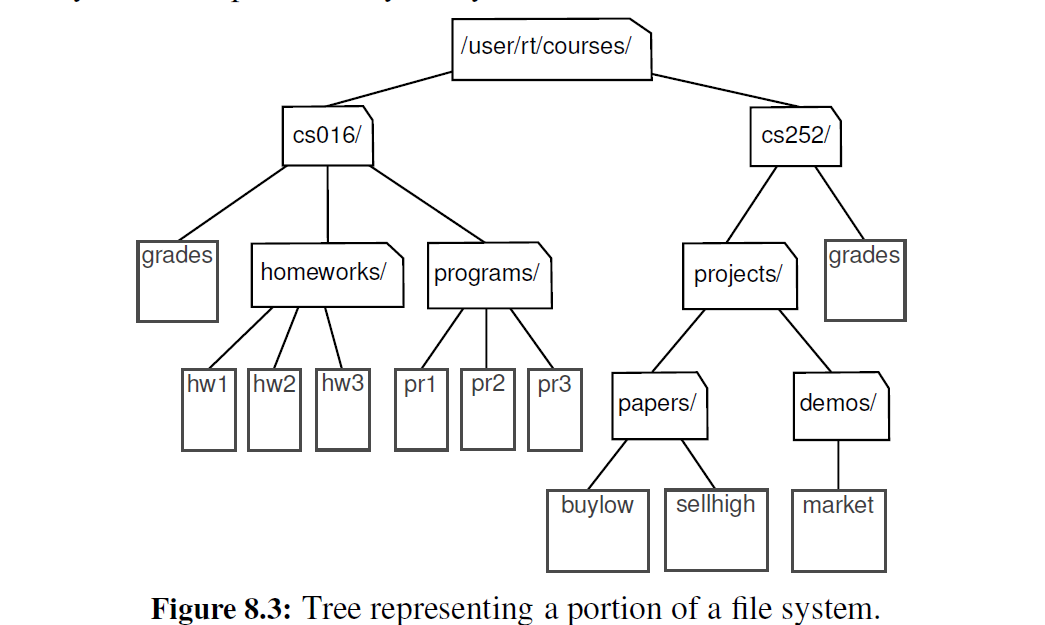

**R-8.5** Implement an algorithm, relying only on the BinaryTree operations, that counts the number of leaves in a binary tree that are the left child of their respective parent.

In [7]:
class Tree:
    """Abstract base class representing a tree structure."""

    class Position:
        """An abstraction representing the location of a single element."""

        def element(self):
            raise NotImplementedError('must be implemented by subclass')

        def __eq__(self, other):
            raise NotImplementedError('must be implemented by subclass')

        def __ne__(self, other):
            return not (self == other)

    # ----- abstract methods -----

    def root(self):
        raise NotImplementedError('must be implemented by subclass')

    def parent(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def num_children(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def children(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def __len__(self):
        raise NotImplementedError('must be implemented by subclass')

    # ----- concrete methods -----

    def is_root(self, p):
        return self.root() == p

    def is_leaf(self, p):
        return self.num_children(p) == 0

    def is_empty(self):
        return len(self) == 0

class BinaryTree(Tree):
    """Abstract base class representing a binary tree structure."""

    # ----- additional abstract methods -----

    def left(self, p):
        """Return a Position representing p's left child."""
        raise NotImplementedError('must be implemented by subclass')

    def right(self, p):
        """Return a Position representing p's right child."""
        raise NotImplementedError('must be implemented by subclass')

    # ----- concrete methods implemented in this class -----

    def sibling(self, p):
        """Return a Position representing p's sibling (or None if no sibling)."""
        parent = self.parent(p)

        if parent is None:
            return None

        if p == self.left(parent):
            return self.right(parent)
        else:
            return self.left(parent)

    def children(self, p):
        """Generate an iteration of Positions representing p's children."""
        if self.left(p) is not None:
            yield self.left(p)

        if self.right(p) is not None:
            yield self.right(p)

class LinkedBinaryTree(BinaryTree):

    class Node:
        def __init__(self, element, parent=None, left=None, right=None):
            self.element = element
            self.parent = parent
            self.left = left
            self.right = right

    class Position(BinaryTree.Position):

        def __init__(self, node):
            self.node = node

        def element(self):
            return self.node.element

        def __eq__(self, other):
            return isinstance(other, type(self)) and other.node is self.node

    def __init__(self):
        self._root = None
        self._size = 0

    def __len__(self):
        return self._size

    def root(self):
        return self.Position(self._root) if self._root else None

    def parent(self, p):
        node = p.node.parent
        return self.Position(node) if node else None

    def left(self, p):
        node = p.node.left
        return self.Position(node) if node else None

    def right(self, p):
        node = p.node.right
        return self.Position(node) if node else None
    
    def num_children(self, p):
        count = 0
        if self.left(p) is not None:
            count += 1
        if self.right(p) is not None:
            count += 1
        return count


    # utility methods

    def add_root(self, e):
        self._root = self.Node(e)
        self._size = 1
        return self.Position(self._root)

    def add_left(self, p, e):
        node = self.Node(e, p.node)
        p.node.left = node
        self._size += 1
        return self.Position(node)

    def add_right(self, p, e):
        node = self.Node(e, p.node)
        p.node.right = node
        self._size += 1
        return self.Position(node)
    

In [13]:
def leftLeaves(T, root= None):
    if T.is_empty():
        return 0
    if root is None:
        root = T.root()
    izqHojas = 0
    hijoIzq = T.left(root)
    if hijoIzq is not None:
        if T.is_leaf(hijoIzq):
            izqHojas += 1
        else:
            izqHojas += leftLeaves(T, hijoIzq)
    hijoDer = T.right(root)
    if hijoDer is not None:
        izqHojas += leftLeaves(T, hijoDer)
    return izqHojas

In [16]:
T = LinkedBinaryTree()
r = T.add_root("A")
b = T.add_left(r, "B")
c = T.add_right(r, "C")
d = T.add_left(b, "D")
e = T.add_right(b, "E")
f = T.add_left(c, "F")
g = T.add_left(d, "G")
h = T.add_right(d, "H")
i = T.add_left(e, "I")
print("Número de hojas izquierdas: ", leftLeaves(T))

Número de hojas izquierdas:  3


**R-8.7** What are the minimum and maximum number of internal and external nodes in an improper binary tree with $n$ nodes?

Los valores de los nodos van a depender de qué tan ramificado armemos el árbol con esos n nodos. Si lo estructuramos en forma de línea recta hacia abajo (como una lista donde cada nodo solo tiene un hijo), tendríamos el mínimo de nodos externos, que es 1, y el máximo de nodos internos, que sería n - 1. Por el otro lado, si armamos el árbol lo más compacto posible forzando que los nodos tengan dos hijos para que quede más ancho, alcanzaríamos el máximo de nodos externos (las hojas), que es n / 2, y el mínimo de nodos internos, que sería n / 2.

**R-8.10** Give a direct implementation of the num_children method within the class BinaryTree.

In [17]:
class Tree:
    """Abstract base class representing a tree structure."""

    class Position:
        """An abstraction representing the location of a single element."""

        def element(self):
            raise NotImplementedError('must be implemented by subclass')

        def __eq__(self, other):
            raise NotImplementedError('must be implemented by subclass')

        def __ne__(self, other):
            return not (self == other)

    # ----- abstract methods -----

    def root(self):
        raise NotImplementedError('must be implemented by subclass')

    def parent(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def num_children(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def children(self, p):
        raise NotImplementedError('must be implemented by subclass')

    def __len__(self):
        raise NotImplementedError('must be implemented by subclass')

    # ----- concrete methods -----

    def is_root(self, p):
        return self.root() == p

    def is_leaf(self, p):
        return self.num_children(p) == 0

    def is_empty(self):
        return len(self) == 0

class BinaryTree(Tree):
    """Abstract base class representing a binary tree structure."""

    # ----- additional abstract methods -----

    def left(self, p):
        """Return a Position representing p's left child."""
        raise NotImplementedError('must be implemented by subclass')

    def right(self, p):
        """Return a Position representing p's right child."""
        raise NotImplementedError('must be implemented by subclass')

    # ----- concrete methods implemented in this class -----

    def sibling(self, p):
        """Return a Position representing p's sibling (or None if no sibling)."""
        parent = self.parent(p)

        if parent is None:
            return None

        if p == self.left(parent):
            return self.right(parent)
        else:
            return self.left(parent)

    def children(self, p):
        """Generate an iteration of Positions representing p's children."""
        if self.left(p) is not None:
            yield self.left(p)

        if self.right(p) is not None:
            yield self.right(p)
    
    def num_children(self, p):
        count = 0
        if self.left(p) is not None:
            count += 1
        if self.right(p) is not None:
            count += 1
        return count


class LinkedBinaryTree(BinaryTree):

    class Node:
        def __init__(self, element, parent=None, left=None, right=None):
            self.element = element
            self.parent = parent
            self.left = left
            self.right = right

    class Position(BinaryTree.Position):

        def __init__(self, node):
            self.node = node

        def element(self):
            return self.node.element

        def __eq__(self, other):
            return isinstance(other, type(self)) and other.node is self.node

    def __init__(self):
        self._root = None
        self._size = 0

    def __len__(self):
        return self._size

    def root(self):
        return self.Position(self._root) if self._root else None

    def parent(self, p):
        node = p.node.parent
        return self.Position(node) if node else None

    def left(self, p):
        node = p.node.left
        return self.Position(node) if node else None

    def right(self, p):
        node = p.node.right
        return self.Position(node) if node else None
    

    # utility methods

    def add_root(self, e):
        self._root = self.Node(e)
        self._size = 1
        return self.Position(self._root)

    def add_left(self, p, e):
        node = self.Node(e, p.node)
        p.node.left = node
        self._size += 1
        return self.Position(node)

    def add_right(self, p, e):
        node = self.Node(e, p.node)
        p.node.right = node
        self._size += 1
        return self.Position(node)
    

In [21]:
T = LinkedBinaryTree()
r = T.add_root("A")
b = T.add_left(r, "B")
c = T.add_right(r, "C")
d = T.add_left(b, "D")
e = T.add_right(b, "E")
f = T.add_left(c, "F")
g = T.add_left(d, "G")
h = T.add_right(d, "H")
i = T.add_left(e, "I")

print("Hijos de la raíz A:", T.num_children(r)) 
print("Hijos del nodo B:", T.num_children(b))   
print("Hijos del nodo D:", T.num_children(d))   
print("Hijos del nodo E:", T.num_children(e))
print("Hijos del nodo F:", T.num_children(f))

Hijos de la raíz A: 2
Hijos del nodo B: 2
Hijos del nodo D: 2
Hijos del nodo E: 1
Hijos del nodo F: 0


**R-8.11** Find the value of the arithmetic expression associated with each subtree of the binary tree of Figure 8.8.

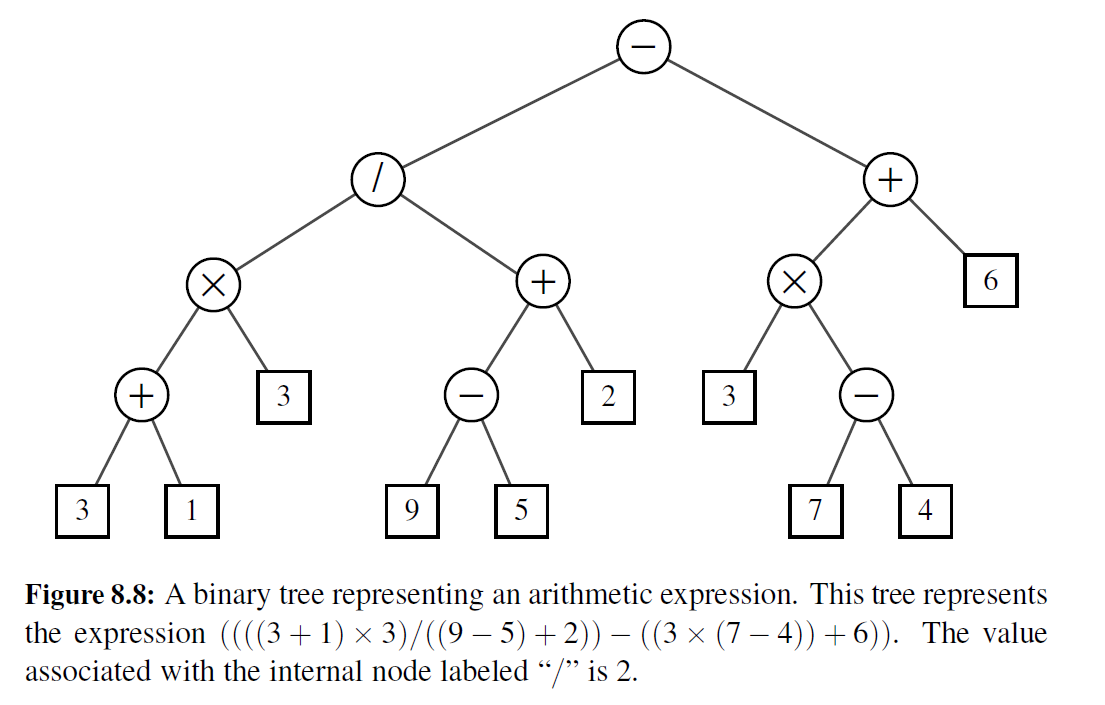

| Nivel | Subárbol Izquierdo (Exterior) | Subárbol Izquierdo (Interior) | Subárbol Derecho (Interior) | Subárbol Derecho (Exterior) |
| :---: | :---: | :---: | :---: | :---: |
| **1 (Raíz)** | | **Nodo `-`: -13** | | |
| **2** | **Nodo `/`: 2** | | **Nodo `+`: 15** | |
| **3** | **Nodo `x`: 12** | **Nodo `+: 6`** | **Nodo `x`: 9** | Hoja **`6`** |
| **4** | **Nodo `+`: 4** <br> Hoja **`3`** | **Nodo `-`: 4** <br> Hoja **`2`** | Hoja **`3`** <br> **Nodo `-`: 3** | |
| **5** | Hojas **`3`** y **`1`** | Hojas **`9`** y **`5`** | Hojas **`7`** y **`4`** | |

**R-8.12** Draw an arithmetic expression tree that has four external nodes, storing the numbers 1, 5, 6, and 7 (with each number stored in a distinct external node, but not necessarily in this order), and has three internal nodes, each storing an operator from the set $\{+, -, \times, /\}$, so that the value of the root is 21. The operators may return and act on fractions, and an operator may be used more than once.

**R-8.13** Draw the binary tree representation of the following arithmetic expression: “$((((5 + 2) * (2 - 1))/((2 + 9) + ((7 - 2) - 1)) * 8)$”.